# Parte 0: Pipeline de Dados e Análise Exploratória

Este notebook documenta o pipeline de preparação dos dados:
1. Carregamento e limpeza dos dados brutos
2. Feature Engineering (forma recente, h2h, discretização)
3. Análise Exploratória dos Dados (EDA)

> **Nota:** O ficheiro `dataset.csv` já se encontra processado. Este notebook serve de documentação e reprodução do pipeline para efeitos de relatório.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
sns.set_theme(style='whitegrid', palette='muted')


os.makedirs('plots', exist_ok=True)
DATASET_PATH = '../dataset/dataset.csv'
print('Packages loaded successfully.')

Packages loaded successfully.


## 1. Carregamento e Limpeza (`1_load_and_clean.py`)

Os dados brutos foram obtidos em [football-data.co.uk](https://www.football-data.co.uk/portugalm.php).
Cada ficheiro CSV corresponde a uma época da Liga Portuguesa.

### Porque foram renomeadas as colunas?

O dataset original usa nomenclatura da fonte (`HomeTeam`, `FTHG`, `B365H`, etc.), que é verbosa e inconsistente.
Renomear para nomes curtos e em minúsculas (`ht`, `hg`, `h_odds`, etc.) torna o código mais conciso, menos propenso a erros de digitação e compatível com a convenção `snake_case` do Python.

| Original       | Renomeado | Significado                         |
|----------------|-----------|-------------------------------------|
| `Date`         | `date`    | Data do jogo                        |
| `HomeTeam`     | `ht`      | Equipa da casa (*home team*)        |
| `AwayTeam`     | `at`      | Equipa visitante (*away team*)      |
| `FTHG`         | `hg`      | Golos da casa (*home goals*)        |
| `FTAG`         | `ag`      | Golos fora (*away goals*)           |
| `FTR`          | `result`  | Resultado final (H / D / A)         |
| `B365H`        | `h_odds`  | Odd de vitória da casa (Bet365)     |
| `B365D`        | `d_odds`  | Odd de empate (Bet365)              |
| `B365A`        | `a_odds`  | Odd de vitória fora (Bet365)        |

### Porque foram normalizados os nomes das equipas?

O nome de algumas equipas varia consoante a época (erros de digitação, abreviaturas diferentes ou espaços extra na fonte).
Sem normalização, a mesma equipa apareceria como entidades distintas, o que corromperia o cálculo da **forma recente** e dos **confrontos directos** (que dependem de cruzar jogos históricos por nome de equipa).

Exemplos de inconsistências corrigidas:

| Nome original   | Nome normalizado |
|-----------------|------------------|
| `sp lisbon`     | `sporting`       |
| `estrela`       | `est amadora`    |
| `feirense ` *(espaço no final)* | `feirense` |

In [2]:
# Pipeline de limpeza (reprodução do script 1_load_and_clean.py)
# Neste caso carregamos directamente o dataset já processado

COLUMNS_RENAME = {
    'Date': 'date', 'HomeTeam': 'ht', 'AwayTeam': 'at',
    'FTHG': 'hg', 'FTAG': 'ag', 'FTR': 'result',
    'B365H': 'h_odds', 'B365D': 'd_odds', 'B365A': 'a_odds',
}

BAD_TEAM_NAMES = {
    'sp lisbon': 'sporting',
    'estrela': 'est amadora',
    'feirense ': 'feirense',
}

print('Mapeamento de colunas:')
for k, v in COLUMNS_RENAME.items():
    print(f'  {k:15s} -> {v}')

print('\nNormalização de nomes de equipas:')
for k, v in BAD_TEAM_NAMES.items():
    print(f'  "{k}" -> "{v}"')

Mapeamento de colunas:
  Date            -> date
  HomeTeam        -> ht
  AwayTeam        -> at
  FTHG            -> hg
  FTAG            -> ag
  FTR             -> result
  B365H           -> h_odds
  B365D           -> d_odds
  B365A           -> a_odds

Normalização de nomes de equipas:
  "sp lisbon" -> "sporting"
  "estrela" -> "est amadora"
  "feirense " -> "feirense"


## 2. Feature Engineering (`2_feature_engineering.py`)

Para cada jogo foram calculadas as seguintes features com base nos últimos **5 jogos** de cada equipa:

| Feature | Descrição |
|---|---|
| `ht_form_points` | Pontos nos últimos 5 jogos da equipa da casa (float) |
| `ht_form_goals_scored` | Golos marcados nos últimos 5 jogos da equipa da casa |
| `ht_form_goals_conceded` | Golos sofridos nos últimos 5 jogos da equipa da casa |
| `at_form_*` | Equivalentes para a equipa visitante |
| `ht_home_form_*` | Forma em casa (últimos 5 jogos em casa) |
| `at_away_form_*` | Forma fora (últimos 5 jogos fora) |
| `h2h_*` | Histórico de confrontos directos |

### Variáveis Derivadas

| Variável | Tipo | Descrição |
|---|---|---|
| `ht_form` | **Inteiro (0–15)** | Soma de pontos nos últimos 5 jogos da casa |
| `at_form` | **Inteiro (0–15)** | Soma de pontos nos últimos 5 jogos da equipa visitante |
| `ht_attack` | Categórico (4 classes) | Capacidade ofensiva da casa: `weak / average / above avg / strong` |
| `at_attack` | Categórico (4 classes) | Capacidade ofensiva da equipa visitante |
| `h2h_dominance` | Categórico (3 classes) | Dominância h2h: `home_dominant / away_dominant / balanced` |
| `odds_favorite` | Categórico (3 classes) | Favorito segundo odds: `home / away / balanced` |

> **Nota:** `ht_form` e `at_form` são representadas como inteiros (soma exacta de pontos, 0–15) preservando toda a informação ordinal sem perda por discretização. As restantes variáveis categóricas (`ht_attack`, `h2h_dominance`, `odds_favorite`) mantêm um número reduzido de classes porque são usadas como nós da Rede Bayesiana (Part 1) — converter para inteiros tornaria a CPT intratável com o tamanho do dataset.

## 3. Carregamento do Dataset Final

In [3]:
df = pd.read_csv(DATASET_PATH, parse_dates=['date'])
print(f'Shape: {df.shape}')
print(f'Período: {df["date"].min().date()} → {df["date"].max().date()}')
df.head(3)

Shape: (5583, 30)
Período: 2006-01-06 → 2026-01-26


,date,ht,at,hg,ag,result,h_odds,d_odds,a_odds,ht_form_points,...,at_away_form_goals_scored,h2h_home_wins,h2h_draws,h2h_away_wins,ht_form,at_form,ht_attack,at_attack,h2h_dominance,odds_favorite
0,2006-01-06,belenenses,gil vicente,0,2,A,1.80,3.25,4.00,10.0,...,0.0,1.0,1.0,2.0,10,6,average,average,balanced,home
1,2006-01-06,nacional,setubal,2,2,D,1.72,3.25,4.33,9.0,...,5.0,0.0,0.0,2.0,9,9,average,weak,balanced,home
2,2006-01-07,maritimo,academica,2,2,D,1.72,3.25,4.33,7.0,...,3.0,0.0,1.0,3.0,7,7,average,average,balanced,home


In [4]:
print('Tipos de dados:')
print(df.dtypes)
print(f'\nValores nulos por coluna:')
print(df.isnull().sum()[df.isnull().sum() > 0])

Tipos de dados:
date                         datetime64[ns]
ht                                   object
at                                   object
hg                                    int64
ag                                    int64
result                               object
h_odds                              float64
d_odds                              float64
a_odds                              float64
ht_form_points                      float64
ht_form_goals_scored                float64
ht_form_goals_conceded              float64
ht_form_wins                        float64
at_form_points                      float64
at_form_goals_scored                float64
at_form_goals_conceded              float64
at_form_wins                        float64
ht_home_form_points                 float64
ht_home_form_goals_scored           float64
at_away_form_points                 float64
at_away_form_goals_scored           float64
h2h_home_wins                       float64
h2h_draws       

## 4. Análise Exploratória dos Dados (EDA)

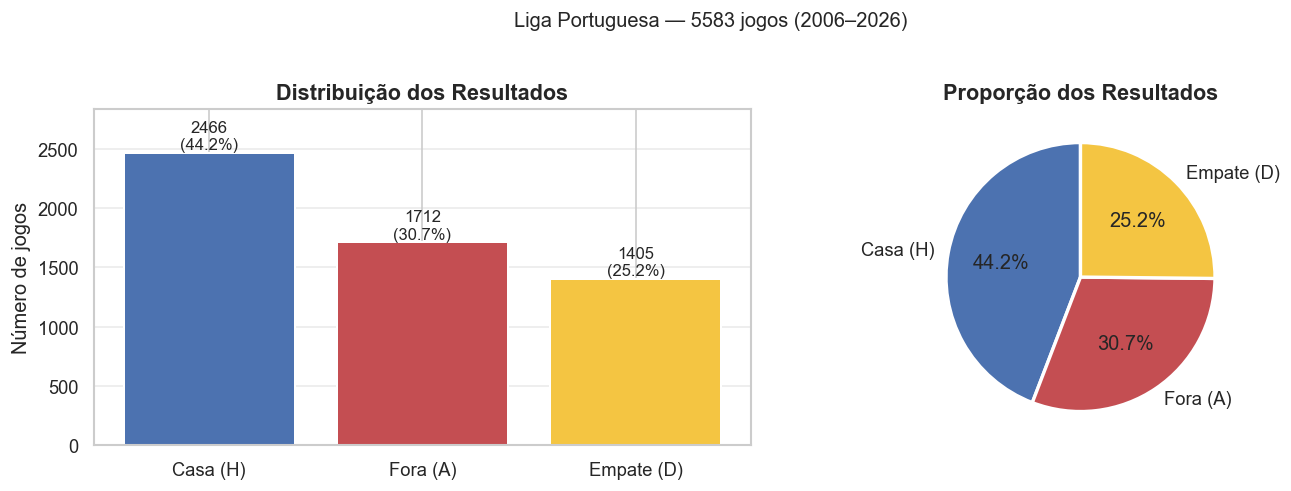

In [5]:
# Distribuição do resultado
result_counts = df['result'].value_counts()
RESULT_COLORS = {'H': '#4C72B0', 'D': '#F4C542', 'A': '#C44E52'}
labels_map = {'H': 'Casa (H)', 'D': 'Empate (D)', 'A': 'Fora (A)'}
bar_colors = [RESULT_COLORS[r] for r in result_counts.index]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
bars = axes[0].bar([labels_map[r] for r in result_counts.index],
                   result_counts.values, color=bar_colors, edgecolor='white', linewidth=1.2)
for bar, val in zip(bars, result_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 f'{val}\n({val/len(df)*100:.1f}%)', ha='center', fontsize=10)
axes[0].set_title('Distribuição dos Resultados', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Número de jogos')
axes[0].set_ylim(0, result_counts.max() * 1.15)
axes[0].grid(axis='y', alpha=0.4)

# Pie chart
axes[1].pie(result_counts.values,
            labels=[labels_map[r] for r in result_counts.index],
            colors=bar_colors, autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Proporção dos Resultados', fontsize=13, fontweight='bold')

plt.suptitle(f'Liga Portuguesa — {len(df)} jogos (2006–2026)', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('plots/p0_result_distribution.png', bbox_inches='tight')
plt.show()

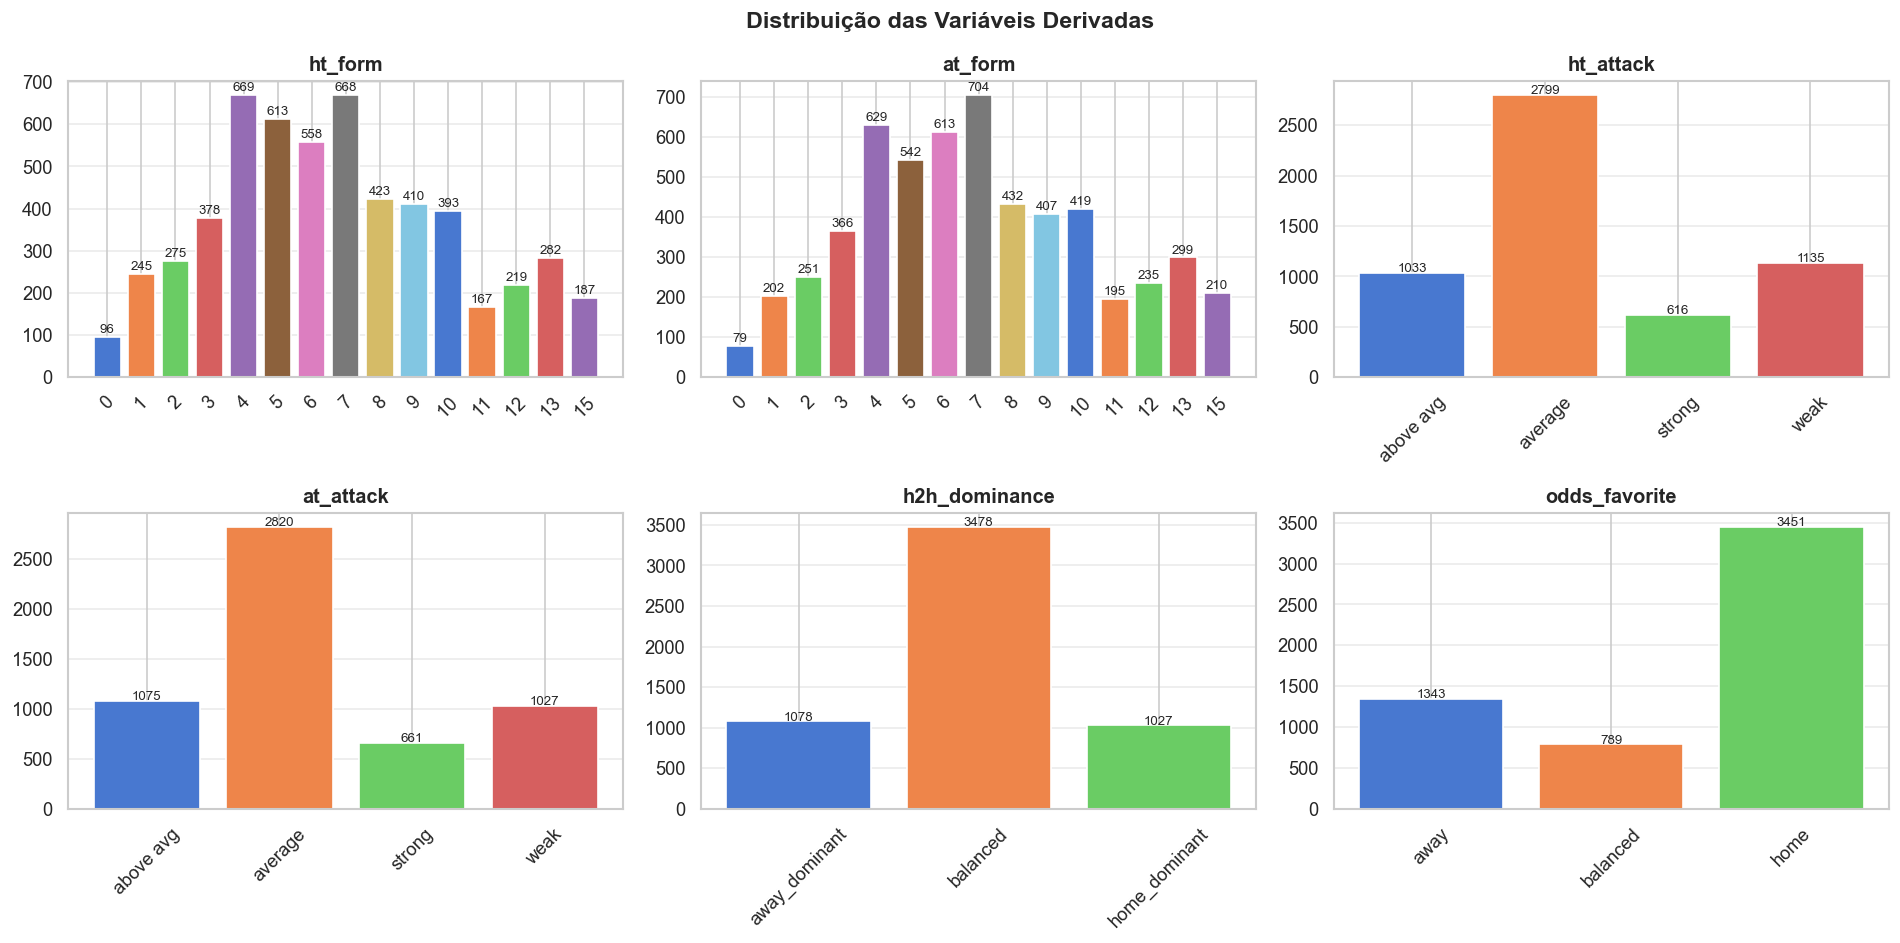

In [6]:
# Garantir que a pasta plots existe
os.makedirs('plots', exist_ok=True)

# Distribuição das variáveis discretizadas
disc_cols = ['ht_form', 'at_form', 'ht_attack', 'at_attack', 'h2h_dominance', 'odds_favorite']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for ax, col in zip(axes, disc_cols):
    counts = df[col].value_counts().sort_index()
    bars = ax.bar([str(v) for v in counts.index], counts.values,
                  color=sns.color_palette('muted', len(counts)),
                  edgecolor='white', linewidth=1)
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                f'{val}', ha='center', fontsize=8)
    ax.set_title(col, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.4)

plt.suptitle('Distribuição das Variáveis Derivadas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/p0_discrete_vars.png', bbox_inches='tight')
plt.show()

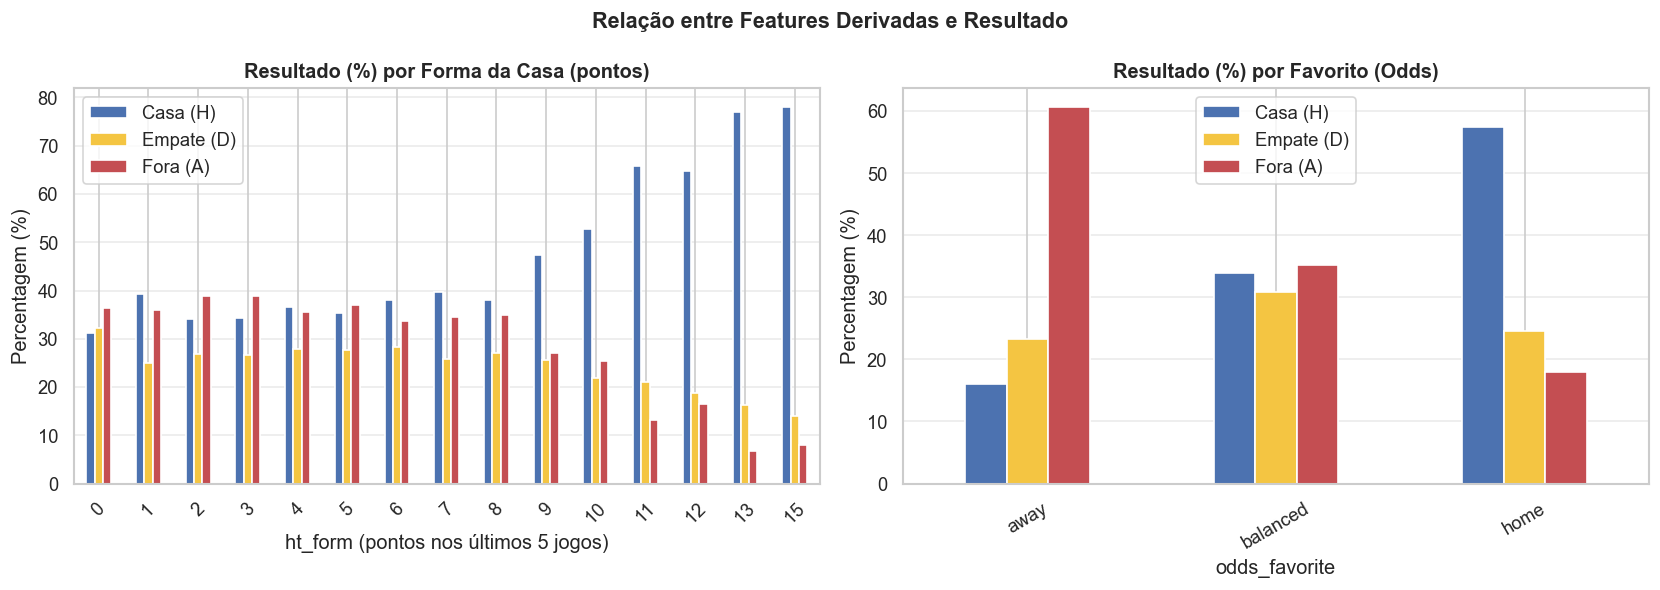

In [7]:
# Resultado por forma da equipa da casa
form_values = sorted(df['ht_form'].unique())
ht_form_result = df.groupby(['ht_form', 'result']).size().unstack(fill_value=0)
ht_form_result = ht_form_result.reindex(form_values)
ht_form_result_pct = ht_form_result.div(ht_form_result.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ht_form_result_pct[['H', 'D', 'A']].plot(kind='bar', ax=axes[0],
    color=['#4C72B0', '#F4C542', '#C44E52'], edgecolor='white')
axes[0].set_title('Resultado (%) por Forma da Casa (pontos)', fontweight='bold')
axes[0].set_xlabel('ht_form (pontos nos últimos 5 jogos)')
axes[0].set_ylabel('Percentagem (%)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(['Casa (H)', 'Empate (D)', 'Fora (A)'])
axes[0].grid(axis='y', alpha=0.4)

# Resultado por odds_favorite
odds_fav_result = df.groupby(['odds_favorite', 'result']).size().unstack(fill_value=0)
odds_fav_result_pct = odds_fav_result.div(odds_fav_result.sum(axis=1), axis=0) * 100
odds_fav_result_pct[['H', 'D', 'A']].plot(kind='bar', ax=axes[1],
    color=['#4C72B0', '#F4C542', '#C44E52'], edgecolor='white')
axes[1].set_title('Resultado (%) por Favorito (Odds)', fontweight='bold')
axes[1].set_xlabel('odds_favorite')
axes[1].set_ylabel('Percentagem (%)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(['Casa (H)', 'Empate (D)', 'Fora (A)'])
axes[1].grid(axis='y', alpha=0.4)

plt.suptitle('Relação entre Features Derivadas e Resultado', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/p0_form_vs_result.png', bbox_inches='tight')
plt.show()

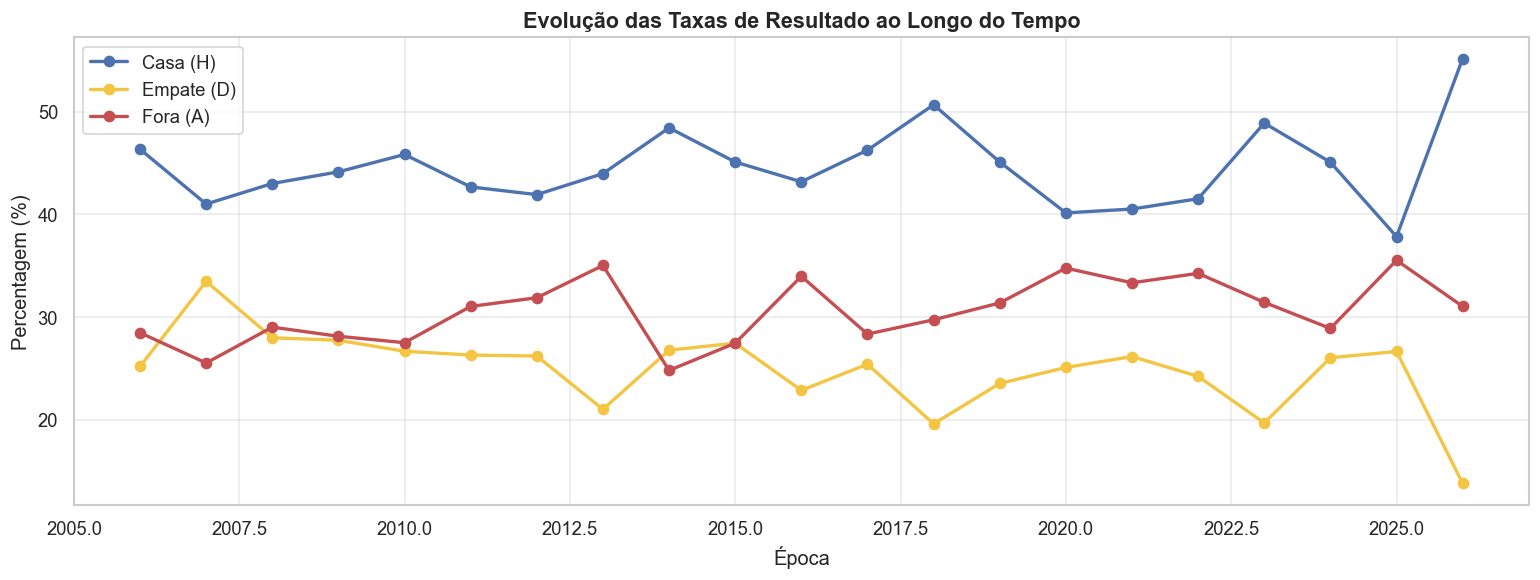

In [8]:
# Distribuição das odds ao longo do tempo
df['year'] = df['date'].dt.year
yearly_results = df.groupby(['year', 'result']).size().unstack(fill_value=0)
yearly_results_pct = yearly_results.div(yearly_results.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(13, 5))
yearly_results_pct[['H', 'D', 'A']].plot(ax=ax, marker='o', linewidth=2,
    color=['#4C72B0', '#F4C542', '#C44E52'])
ax.set_title('Evolução das Taxas de Resultado ao Longo do Tempo', fontsize=13, fontweight='bold')
ax.set_xlabel('Época')
ax.set_ylabel('Percentagem (%)')
ax.legend(['Casa (H)', 'Empate (D)', 'Fora (A)'])
ax.grid(alpha=0.4)
plt.tight_layout()
plt.savefig('plots/p0_results_over_time.png', bbox_inches='tight')
plt.show()

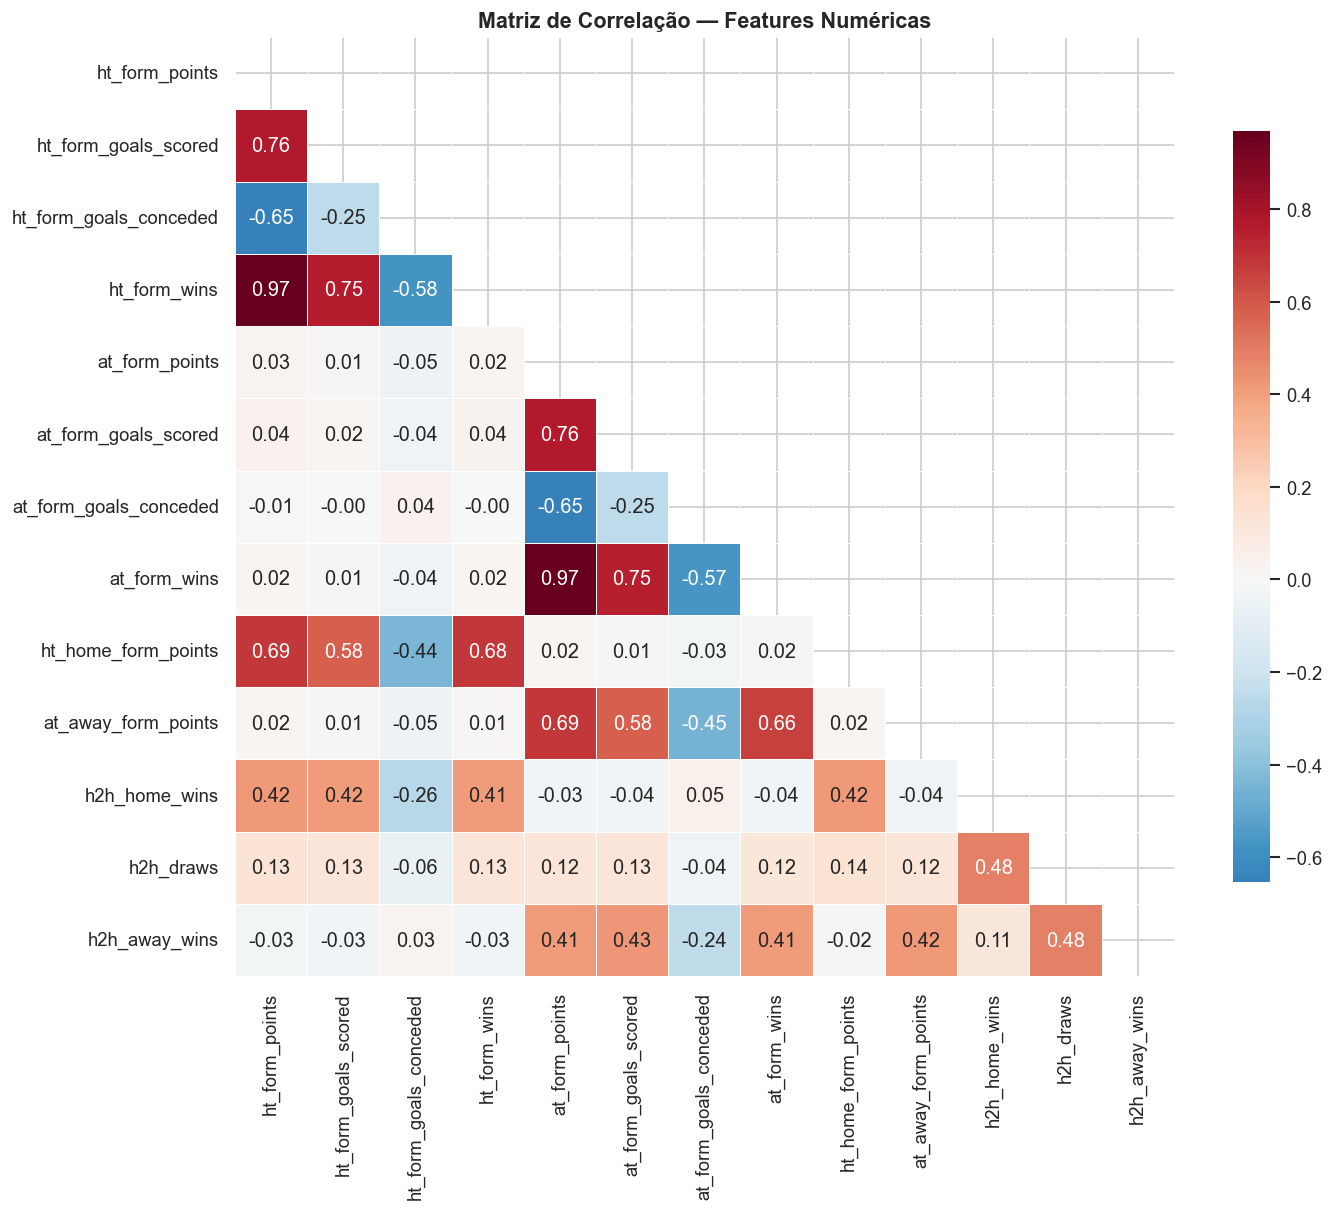

In [9]:
# Matriz de correlação das features numéricas
numeric_cols = [
    'ht_form_points', 'ht_form_goals_scored', 'ht_form_goals_conceded', 'ht_form_wins',
    'at_form_points', 'at_form_goals_scored', 'at_form_goals_conceded', 'at_form_wins',
    'ht_home_form_points', 'at_away_form_points',
    'h2h_home_wins', 'h2h_draws', 'h2h_away_wins'
]
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Matriz de Correlação — Features Numéricas', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/p0_correlation_matrix.png', bbox_inches='tight')
plt.show()

In [10]:
# Estatísticas descritivas das features numéricas por resultado
print('=== Média das features por resultado ===')
summary = df.groupby('result')[['ht_form_points', 'at_form_points',
                                 'ht_form_goals_scored', 'at_form_goals_scored',
                                 'h2h_home_wins', 'h2h_away_wins']].mean().round(2)
print(summary.to_string())
print(f'\nTotal de jogos: {len(df)}')
print(f'Equipas únicas: {df["ht"].nunique()}')
print(f'Épocas: {df["year"].min()} – {df["year"].max()}')

=== Média das features por resultado ===
        ht_form_points  at_form_points  ht_form_goals_scored  at_form_goals_scored  h2h_home_wins  h2h_away_wins
result                                                                                                          
A                 5.79            8.26                  5.45                  7.59           2.64           5.89
D                 6.29            6.77                  5.74                  6.14           3.49           4.11
H                 7.66            6.20                  7.04                  5.74           5.46           3.07

Total de jogos: 5583
Equipas únicas: 38
Épocas: 2006 – 2026


### Class Imbalance e Class Weights

Como o dataset apresenta desequilíbrio (a classe Empate é minoritária), importa mitigar o viés usando a abordagem de `class_weights` balanceados nos futuros classificadores.

In [11]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array(['A', 'D', 'H'])
weights = compute_class_weight('balanced', classes=classes, y=df['result'])
class_weights_dict = dict(zip(classes, weights))
print('Class Weights a aplicar nos próximos passos:', class_weights_dict)

Class Weights a aplicar nos próximos passos: {np.str_('A'): np.float64(1.0870327102803738), np.str_('D'): np.float64(1.3245551601423489), np.str_('H'): np.float64(0.7546634225466342)}
